# Reinforcement Learning pada Game Snake: Q-Learning Tabular
**Tugas Praktikum Reinforcement Learning**

Faiz Farrosian Karim / 5054251027

Link Demo: https://youtu.be/QOHi3zgeZOM

Notebook ini membangun *agent* yang belajar bermain Snake **tanpa diberi contoh benar/salah** (bukan supervised learning). Agent hanya berinteraksi dengan *environment*, menerima *reward*, lalu memperbaiki strateginya lewat **trial-and-error**.

**Alur notebook**

| No | Bagian | Isi |
|---|---|---|
| 0 | Konsep | Pemetaan konsep RL ke project ini |
| 1 | Setup | Import, seed, konfigurasi |
| 2 | Environment | `SnakeEnv` (API gaya Gym) + alasan desain state dan reward |
| 3 | Agent | Random (baseline), Q-Learning, SARSA + hubungan kode dengan konsep RL |
| 4 | Training & kurva learning | 5.000 episode, score / reward / panjang episode |
| 5 | Evaluasi policy akhir | 100 episode (epsilon = 0) vs agent random |
| 6 | Q-Learning vs SARSA | Perbandingan multi-seed |
| 7 | Eksperimen hyperparameter | alpha, gamma, epsilon decay |
| 8 | Visualisasi nilai Q | Heatmap Q untuk state penting |
| 9 | Replay | Animasi GIF satu episode agent terlatih |
| 10 | Kesimpulan | Ringkasan, keterbatasan, pengembangan |

## 0. Konsep RL dan Pemetaannya ke Project Ini

Pada RL, **agent** berinteraksi dengan **environment** secara berulang. Pada langkah ke-*t*, agent mengamati **state** $s_t$, memilih **action** $a_t$, lalu environment membalas dengan **reward** $r_{t+1}$ dan state baru $s_{t+1}$. Tujuan agent adalah memaksimalkan **return** (jumlah reward masa depan yang didiskon):

$$G_t = r_{t+1} + \gamma\, r_{t+2} + \gamma^2 r_{t+3} + \dots$$

| Konsep | Arti umum | Di project Snake | Di kode |
|---|---|---|---|
| **Agent** | Pengambil keputusan yang belajar | Ular beserta "otaknya" (Q-table + aturan memilih aksi) | `TabularAgent` |
| **Environment** | Dunia tempat agent bertindak | Papan 10×10, apel, dinding, badan ular | `SnakeEnv` |
| **State** | Gambaran situasi saat ini | 11 fitur biner: bahaya depan/kiri/kanan, arah gerak, posisi apel relatif kepala | `env._get_state()` |
| **Action** | Pilihan yang tersedia | Lurus, belok kiri, belok kanan (relatif arah kepala) | `0, 1, 2` |
| **Reward** | Sinyal baik/buruknya aksi | +10 makan apel, −10 mati / kelaparan, +1 mendekat, −1 menjauh | `env.step()` |
| **Policy** $\pi(s)$ | Aturan memilih aksi di tiap state | $\pi(s)=\arg\max_a Q(s,a)$; saat belajar memakai epsilon-greedy | `agent.act()` / `agent.greedy()` |
| **Value** | Perkiraan return jangka panjang | $Q(s,a)$ dan $V(s)=\max_a Q(s,a)$ disimpan di Q-table | `agent.Q` |
| **Belajar lewat interaksi** | Memperbaiki value dari pengalaman | Update Bellman di tiap langkah, diulang ribuan episode | `agent.update()` di dalam `train()` |
| **Evaluasi strategi** | Mengukur kualitas policy | Policy greedy (epsilon = 0) dimainkan 100 episode dan dibandingkan dengan agent random | `evaluate()` |

## 1. Setup

In [ ]:
# ===== 1. SETUP: import, seed, konfigurasi, gaya grafik =====
import random, time, os
from collections import deque, Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from PIL import Image as PILImage, ImageDraw
try:
    from IPython.display import display            
except ImportError:
    display = print                                # fallback jika dijalankan sebagai skrip biasa

# --- Reproducibility: semua sumber acak dikunci ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# --- Konfigurasi eksperimen (turunkan nilainya jika ingin versi cepat) ---
N_EPISODES = 5000     # episode training utama (minimal 5.000 sesuai tugas)
N_EVAL     = 100      # episode evaluasi policy akhir (epsilon = 0)
N_SEEDS    = 5        # jumlah seed pada eksperimen hyperparameter / perbandingan algoritma
EVAL_SEED  = 12345    # seed environment untuk evaluasi (sama untuk SEMUA agent -> adil)
MA_WINDOW  = 100      # jendela moving average pada kurva learning

# --- Gaya grafik: palet kategorikal tetap, grid tipis, tanpa spine atas/kanan ---
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4']
C_QL, C_SARSA, C_RANDOM = '#2a78d6', '#eb6834', '#8c8b86'
INK = '#1f1f1d'
plt.rcParams.update({
    'figure.dpi': 100, 'savefig.dpi': 110,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#dddcd6', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8c8b86', 'axes.labelcolor': INK,
    'xtick.color': INK, 'ytick.color': INK, 'text.color': INK,
    'axes.titlesize': 11, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'legend.frameon': False, 'font.size': 10,
})
print("Setup selesai. Seed =", SEED)

Setup selesai. Seed = 42


## 2. Environment: `SnakeEnv`

Environment dibuat sendiri (tanpa pygame) dengan API gaya Gym:

- `reset()` → mengembalikan state awal
- `step(action)` → mengembalikan `(state, reward, done, info)`

### Alasan desain state (11 fitur biner)

| Indeks | Fitur | Makna |
|---|---|---|
| 0–2 | `bahaya_lurus`, `bahaya_kiri`, `bahaya_kanan` | Apakah sel di depan / kiri / kanan kepala berupa dinding atau badan ular (**relatif** terhadap arah gerak) |
| 3–6 | `arah_atas/kanan/bawah/kiri` | Arah gerak saat ini (one-hot) |
| 7–10 | `apel_atas/kanan/bawah/kiri` | Posisi apel relatif terhadap kepala (apel bisa di dua arah sekaligus, mis. kanan-atas) |

Alasan pemilihan:

- **Kecil dan relevan.** Dengan posisi absolut seluruh badan, jumlah state meledak dan Q-table tidak mungkin terisi. Fitur ringkas ini hanya memuat informasi yang menentukan keputusan: *apa yang berbahaya sekarang* dan *ke mana apel berada*.
- **Bahaya relatif, bukan absolut.** "Bahaya di kiri" berarti hal yang sama di mana pun kepala berada, sehingga satu pengalaman berlaku untuk banyak situasi (generalisasi).
- **Ruang state efektif hanya 256.** Arah gerak one-hot menyisakan 4 kemungkinan, kombinasi bahaya 2³ = 8, dan posisi apel 8 kombinasi (tiap sumbu: tidak ada / dua arah, dikurangi kasus apel tepat di kepala). Jadi 4 × 8 × 8 = 256 state × 3 aksi = **768 nilai Q** saja.
- **Konsekuensi (keterbatasan).** Agent tidak melihat panjang badan atau bentuk badan yang jauh dari kepala. Dua situasi berbeda bisa tampak identik (*state aliasing*); inilah penyebab utama agent akhirnya terjebak oleh badannya sendiri pada ular yang sudah panjang.

### Alasan desain reward

| Kejadian | Reward | Alasan |
|---|---|---|
| Makan apel | **+10** | Tujuan utama game |
| Mati (dinding / badan) atau kelaparan | **−10** | Hukuman tegas; kematian mengakhiri semua peluang reward berikutnya |
| Langkah yang mendekati apel | **+1** | *Reward shaping*: tanpanya reward hanya muncul saat makan apel (jarang / *sparse*), sehingga belajar dari nol sangat lambat |
| Langkah yang menjauhi apel | **−1** | Pasangan simetris agar berputar-putar tidak menguntungkan |
| 100 langkah tanpa makan | **−10 + episode berakhir** | **Anti-loop**: tanpa ini agent bisa menemukan siklus yang "aman" tetapi tidak pernah makan |

Besar shaping (±1) sengaja jauh lebih kecil dari reward utama (±10) agar agent tidak lebih memilih sekadar mendekati apel daripada benar-benar memakannya atau menghindari kematian.

In [2]:
# ===== 2. ENVIRONMENT: SnakeEnv (API gaya Gym) =====
UP, RIGHT, DOWN, LEFT = 0, 1, 2, 3                       # arah absolut (searah jarum jam)
DIR_VECS = [(0, -1), (1, 0), (0, 1), (-1, 0)]            # (dx, dy); y bertambah ke bawah
STRAIGHT, TURN_LEFT, TURN_RIGHT = 0, 1, 2                # aksi RELATIF terhadap arah gerak
ACTION_NAMES = ['Lurus', 'Belok kiri', 'Belok kanan']
DIR_NAMES = ['Atas', 'Kanan', 'Bawah', 'Kiri']
STATE_NAMES = ['bahaya_lurus', 'bahaya_kiri', 'bahaya_kanan',
               'arah_atas', 'arah_kanan', 'arah_bawah', 'arah_kiri',
               'apel_atas', 'apel_kanan', 'apel_bawah', 'apel_kiri']


class SnakeEnv:
    """Game Snake grid size x size dengan API ala OpenAI Gym.

    reset()        -> state
    step(action)   -> (state, reward, done, info)

    State  : tuple 11 fitur biner (lihat STATE_NAMES)
    Action : 0 = lurus, 1 = belok kiri, 2 = belok kanan (relatif arah kepala)
    Reward : +10 makan apel | -10 mati / kelaparan | +1 mendekat | -1 menjauh
    """

    def __init__(self, size=10, seed=None, reward_apple=10.0, reward_death=-10.0,
                 reward_closer=1.0, reward_farther=-1.0, starve_limit=100):
        self.size = size
        self.reward_apple, self.reward_death = reward_apple, reward_death
        self.reward_closer, self.reward_farther = reward_closer, reward_farther
        self.starve_limit = starve_limit          # anti-loop: maks langkah tanpa makan
        self.rng = random.Random(seed)            # RNG milik environment (reproducible)

    # ---------- siklus episode ----------
    def reset(self, seed=None):
        if seed is not None:
            self.rng.seed(seed)
        mid = self.size // 2
        self.snake = deque([(mid, mid), (mid - 1, mid), (mid - 2, mid)])  # kepala di index 0
        self.body = set(self.snake)               # set -> cek tabrakan O(1)
        self.direction = RIGHT
        self.score = 0
        self.steps = 0
        self.steps_since_food = 0
        self.done = False
        self._place_food()
        return self._get_state()

    def _place_food(self):
        n = self.size
        if len(self.body) >= n * n:               # papan penuh -> menang
            self.food = None
            return
        if len(self.body) < 0.7 * n * n:          # rejection sampling (cepat)
            while True:
                c = (self.rng.randrange(n), self.rng.randrange(n))
                if c not in self.body:
                    self.food = c
                    return
        free = [(x, y) for x in range(n) for y in range(n) if (x, y) not in self.body]
        self.food = self.rng.choice(free)

    # ---------- representasi state ----------
    def _is_danger(self, x, y):
        """Sel berbahaya = di luar papan atau badan ular (ekor tidak dihitung: ia akan bergeser)."""
        if not (0 <= x < self.size and 0 <= y < self.size):
            return True
        return (x, y) in self.body and (x, y) != self.snake[-1]

    def _get_state(self):
        hx, hy = self.snake[0]
        d = self.direction
        fx, fy = self.food
        sx, sy = DIR_VECS[d]                       # lurus
        lx, ly = DIR_VECS[(d - 1) % 4]             # kiri relatif
        rx, ry = DIR_VECS[(d + 1) % 4]             # kanan relatif
        return (int(self._is_danger(hx + sx, hy + sy)),   # 0: bahaya di depan
                int(self._is_danger(hx + lx, hy + ly)),   # 1: bahaya di kiri
                int(self._is_danger(hx + rx, hy + ry)),   # 2: bahaya di kanan
                int(d == UP), int(d == RIGHT), int(d == DOWN), int(d == LEFT),   # 3-6: arah gerak
                int(fy < hy), int(fx > hx), int(fy > hy), int(fx < hx))          # 7-10: apel relatif kepala

    def _terminal_state(self):
        return (0,) * 11 if self.food is None else self._get_state()

    # ---------- dinamika ----------
    def step(self, action):
        assert not self.done, "Episode sudah selesai, panggil reset()"
        if action == TURN_RIGHT:
            self.direction = (self.direction + 1) % 4
        elif action == TURN_LEFT:
            self.direction = (self.direction - 1) % 4
        dx, dy = DIR_VECS[self.direction]
        hx, hy = self.snake[0]
        nx, ny = hx + dx, hy + dy
        new_head = (nx, ny)
        fx, fy = self.food
        old_dist = abs(hx - fx) + abs(hy - fy)    # jarak Manhattan ke apel sebelum bergerak
        self.steps += 1
        self.steps_since_food += 1

        # 1) mati karena dinding
        if not (0 <= nx < self.size and 0 <= ny < self.size):
            self.done = True
            return self._terminal_state(), self.reward_death, True, \
                {'score': self.score, 'steps': self.steps, 'reason': 'wall'}
        # 2) mati karena menabrak badan sendiri (ekor boleh ditempati: ia sedang bergeser)
        eating = new_head == self.food
        if new_head in self.body and new_head != self.snake[-1]:
            self.done = True
            return self._terminal_state(), self.reward_death, True, \
                {'score': self.score, 'steps': self.steps, 'reason': 'body'}

        # 3) bergerak
        if not eating:
            self.body.discard(self.snake.pop())   # ekor maju
        self.snake.appendleft(new_head)
        self.body.add(new_head)

        info = {'reason': None}
        if eating:                                 # makan apel
            self.score += 1
            self.steps_since_food = 0
            reward = self.reward_apple
            self._place_food()
            if self.food is None:                  # papan penuh = menang
                self.done = True
                info.update(score=self.score, steps=self.steps, reason='win')
                return self._terminal_state(), reward, True, info
        else:                                      # reward shaping: mendekat / menjauh
            new_dist = abs(nx - fx) + abs(ny - fy)
            reward = self.reward_closer if new_dist < old_dist else self.reward_farther
            if self.steps_since_food >= self.starve_limit:   # anti-loop
                self.done = True
                info.update(score=self.score, steps=self.steps, reason='starved')
                return self._get_state(), self.reward_death, True, info
        info.update(score=self.score, steps=self.steps)
        return self._get_state(), reward, False, info

### Uji sanity environment
Sebelum dipakai untuk belajar, aturan environment diuji: arah belok, tanda reward, kematian di dinding, dan anti-loop.

In [3]:
# ===== Uji sanity environment =====
env = SnakeEnv(seed=SEED)
s = env.reset()
print("State awal   :", dict(zip(STATE_NAMES, s)))
print("Ular (kepala->ekor):", list(env.snake), "| Apel:", env.food, "| Panjang state:", len(s))

# (a) Belok kiri dari arah KANAN harus menghadap ATAS; apel di depan -> reward mendekat +1
env.reset(); env.food = (8, 5)                     # apel tepat di depan kepala (5,5)
_, r, _, _ = env.step(STRAIGHT);   assert r == 1.0, "mendekat harus +1"
_, r, _, _ = env.step(TURN_LEFT);  assert env.direction == UP and r == -1.0, "menjauh harus -1"

# (b) Menabrak dinding: dari (5,5) menghadap kanan, butuh 5 langkah lurus untuk keluar papan
env.reset(); env.food = (5, 0)
for _ in range(4):
    _, r, done, _ = env.step(STRAIGHT); assert not done
_, r, done, info = env.step(STRAIGHT)
assert done and r == -10.0 and info['reason'] == 'wall'

# (c) Anti-loop: environment dengan batas kelaparan 3 langkah harus mengakhiri episode
e2 = SnakeEnv(seed=1, starve_limit=3); e2.reset(); e2.food = (0, 9)
for _ in range(3):
    _, r, done, info = e2.step(STRAIGHT)
assert done and info['reason'] == 'starved' and r == -10.0

# (d) Satu episode dengan aksi acak
rng = random.Random(0); s = env.reset(); total, done = 0.0, False
while not done:
    s, r, done, info = env.step(rng.randrange(3)); total += r
print("Episode acak :", info, "| total reward =", total)
print("Semua uji sanity lolos")

State awal   : {'bahaya_lurus': 0, 'bahaya_kiri': 0, 'bahaya_kanan': 0, 'arah_atas': 0, 'arah_kanan': 1, 'arah_bawah': 0, 'arah_kiri': 0, 'apel_atas': 1, 'apel_kanan': 0, 'apel_bawah': 0, 'apel_kiri': 1}
Ular (kepala->ekor): [(5, 5), (4, 5), (3, 5)] | Apel: (1, 0) | Panjang state: 11
Episode acak : {'score': 0, 'steps': 15, 'reason': 'wall'} | total reward = -8.0
Semua uji sanity lolos


## 3. Agent dan Hubungannya dengan Konsep RL

Tiga agent dibuat: **Random** (baseline, tanpa belajar), **Q-Learning** (algoritma utama), dan **SARSA** (pembanding).

### Q-Learning (off-policy)

Setiap langkah, setelah agent mengambil aksi $a$ di state $s$ dan mendapat reward $r$ serta state baru $s'$, nilai Q diperbarui dengan **persamaan Bellman**:

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\Big[\, r + \gamma \max_{a'} Q(s',a') - Q(s,a) \,\Big]$$

- $\alpha$ (*learning rate*): seberapa besar nilai lama digeser ke target baru.
- $\gamma$ (*discount factor*): seberapa penting reward masa depan dibanding reward sekarang.
- Bagian dalam kurung siku disebut *TD error*: selisih antara "target" (apa yang baru dialami + perkiraan masa depan) dan perkiraan lama.

### SARSA (on-policy)

Sama seperti di atas, tetapi bagian $\max_{a'}Q(s',a')$ diganti nilai aksi $a'$ yang **benar-benar akan diambil** agent (termasuk aksi eksplorasi acak):

$$Q(s,a) \leftarrow Q(s,a) + \alpha\,\Big[\, r + \gamma\, Q(s',a') - Q(s,a) \,\Big]$$

Akibatnya SARSA ikut "memperhitungkan risiko eksplorasi" sehingga cenderung lebih hati-hati.

### Epsilon-greedy

Agent harus **mencoba** aksi baru (eksplorasi) sekaligus **memakai** yang sudah terbukti baik (eksploitasi). Dengan peluang $\varepsilon$ ia memilih aksi acak, selain itu memilih $\arg\max_a Q(s,a)$. Nilai $\varepsilon$ dimulai dari 1,0 (murni coba-coba) lalu dikalikan faktor *decay* tiap episode.

### Peta kode ↔ konsep

| Bagian kode | Konsep RL |
|---|---|
| `agent.Q` (dict state → 3 nilai) | **Value** ($Q(s,a)$; $V(s)$ = nilai maksimum pada barisnya) |
| `agent.greedy(s)` = $\arg\max_a Q(s,a)$ | **Policy** hasil belajar |
| `agent.act(s)` dengan epsilon | Policy perilaku (eksplorasi vs eksploitasi) |
| `agent.update(...)` | **Proses belajar** (update Bellman) |
| `train()` | **Belajar lewat interaksi**: state → aksi → reward + state baru → update, diulang per episode |
| `evaluate()` dengan epsilon = 0 | **Evaluasi strategi** |

In [4]:
# ===== 3. AGENT: Random (baseline), Q-Learning & SARSA (tabular) =====
class RandomAgent:
    """Baseline: memilih aksi acak seragam, tanpa belajar."""
    def __init__(self, seed=0):
        self.rng = random.Random(seed)

    def act(self, state, explore=False):
        return self.rng.randrange(3)


class TabularAgent:
    """Agent tabular. Q-table (dict: state -> [Q(s,lurus), Q(s,kiri), Q(s,kanan)]) = VALUE.

    - act(): epsilon-greedy saat belajar, greedy murni (argmax Q) saat evaluasi  = POLICY
    - update(): pembaruan Bellman (Q-Learning off-policy / SARSA on-policy)       = PROSES BELAJAR
    """
    def __init__(self, algo='qlearning', alpha=0.1, gamma=0.9, eps_start=1.0,
                 eps_min=0.01, eps_decay=0.995, seed=0):
        assert algo in ('qlearning', 'sarsa')
        self.algo, self.alpha, self.gamma = algo, alpha, gamma
        self.eps, self.eps_min, self.eps_decay = eps_start, eps_min, eps_decay
        self.Q = {}                                # hanya state yang pernah dikunjungi disimpan
        self.rng = random.Random(seed)             # RNG agent (terpisah dari environment)

    def _row(self, s):
        q = self.Q.get(s)
        if q is None:                              # inisialisasi Q = 0 untuk state baru
            q = self.Q[s] = [0.0, 0.0, 0.0]
        return q

    def greedy(self, s):
        """Policy greedy: argmax_a Q(s,a); tie (mis. state baru) dipecah acak."""
        q = self.Q.get(s)
        if q is None:
            return self.rng.randrange(3)
        m = max(q)
        if q.count(m) == 1:
            return q.index(m)
        return self.rng.choice([a for a in range(3) if q[a] == m])

    def act(self, s, explore=True):
        """Epsilon-greedy: dengan peluang eps coba aksi acak (eksplorasi), selain itu greedy (eksploitasi)."""
        if explore and self.rng.random() < self.eps:
            return self.rng.randrange(3)
        return self.greedy(s)

    def update(self, s, a, r, s2, a2, done):
        """Update Bellman:  Q(s,a) <- Q(s,a) + alpha * (target - Q(s,a))"""
        q = self._row(s)
        if done:
            target = r                                         # tidak ada masa depan setelah terminal
        elif self.algo == 'qlearning':
            target = r + self.gamma * max(self._row(s2))       # Q-Learning: nilai aksi TERBAIK di s'
        else:
            target = r + self.gamma * self._row(s2)[a2]        # SARSA: nilai aksi yang BENAR-BENAR diambil
        q[a] += self.alpha * (target - q[a])

    def decay(self):
        self.eps = max(self.eps_min, self.eps * self.eps_decay)

### Fungsi training dan evaluasi
`train()` menjalankan loop interaksi agent–environment; `evaluate()` memainkan policy greedy (tanpa eksplorasi) pada seed environment yang tetap.

In [5]:
# ===== 4. FUNGSI TRAINING & EVALUASI =====
def train(algo='qlearning', episodes=5000, seed=0, env_kwargs=None, log_every=None, **hp):
    """Loop interaksi agent-environment. Mengembalikan (agent, log per episode)."""
    env = SnakeEnv(seed=seed, **(env_kwargs or {}))
    agent = TabularAgent(algo=algo, seed=seed + 1, **hp)
    log = {'score': [], 'reward': [], 'length': [], 'epsilon': []}
    for ep in range(episodes):
        s = env.reset()
        a = agent.act(s)                           # pilih aksi awal (epsilon-greedy)
        done, total = False, 0.0
        while not done:
            s2, r, done, info = env.step(a)        # environment memberi state baru + reward
            a2 = None if done else agent.act(s2)   # aksi berikutnya (dipakai SARSA)
            agent.update(s, a, r, s2, a2, done)    # agent belajar dari pengalaman ini
            s, a = s2, a2
            total += r
        log['score'].append(info['score'])
        log['reward'].append(total)
        log['length'].append(info['steps'])
        log['epsilon'].append(agent.eps)
        agent.decay()                              # kurangi eksplorasi seiring waktu
        if log_every and (ep + 1) % log_every == 0:
            print(f"Episode {ep+1:5d} | epsilon={agent.eps:.3f} | "
                  f"rata2 score {log_every} terakhir = {np.mean(log['score'][-log_every:]):6.2f} | "
                  f"rata2 reward = {np.mean(log['reward'][-log_every:]):7.1f} | "
                  f"state dikunjungi = {len(agent.Q)}")
    return agent, log


def evaluate(agent, n_episodes=100, seed=12345, env_kwargs=None):
    """Evaluasi policy TANPA eksplorasi (epsilon = 0). Seed environment sama -> perbandingan adil."""
    env = SnakeEnv(**(env_kwargs or {}))
    out = {'score': [], 'reward': [], 'length': [], 'reason': []}
    for i in range(n_episodes):
        s = env.reset(seed=seed + i)
        done, total = False, 0.0
        while not done:
            s, r, done, info = env.step(agent.act(s, explore=False))
            total += r
        out['score'].append(info['score'])
        out['reward'].append(total)
        out['length'].append(info['steps'])
        out['reason'].append(info['reason'])
    return out


def moving_average(x, w=100):
    x = np.asarray(x, dtype=float)
    return np.convolve(x, np.ones(w) / w, mode='valid')


REASON_ID = {'wall': 'Menabrak dinding', 'body': 'Menabrak badan', 'starved': 'Kelaparan (loop)', 'win': 'Menang'}

## 4. Training Utama dan Kurva Learning

Q-Learning dilatih 5.000 episode. Untuk setiap episode dicatat **score** (jumlah apel), **total reward**, dan **panjang episode** (jumlah langkah). Log di bawah menampilkan kemajuan tiap 500 episode.

In [6]:
# ===== 5. TRAINING UTAMA: Q-Learning (alpha=0.1, gamma=0.9, epsilon decay 0.995) =====
HP_MAIN = dict(alpha=0.1, gamma=0.9, eps_start=1.0, eps_min=0.01, eps_decay=0.995)

t0 = time.time()
agent_ql, log_ql = train('qlearning', episodes=N_EPISODES, seed=SEED, log_every=500, **HP_MAIN)
print(f"\nSelesai dalam {time.time()-t0:.1f} detik. Ukuran Q-table: {len(agent_ql.Q)} state "
      f"(dari maksimum nominal 2^11 = 2048)")

Episode   500 | epsilon=0.082 | rata2 score 500 terakhir =   3.51 | rata2 reward =    44.4 | state dikunjungi = 220
Episode  1000 | epsilon=0.010 | rata2 score 500 terakhir =  13.91 | rata2 reward =   209.6 | state dikunjungi = 254
Episode  1500 | epsilon=0.010 | rata2 score 500 terakhir =  15.73 | rata2 reward =   239.1 | state dikunjungi = 256
Episode  2000 | epsilon=0.010 | rata2 score 500 terakhir =  16.48 | rata2 reward =   249.6 | state dikunjungi = 256
Episode  2500 | epsilon=0.010 | rata2 score 500 terakhir =  15.54 | rata2 reward =   235.3 | state dikunjungi = 256
Episode  3000 | epsilon=0.010 | rata2 score 500 terakhir =  14.86 | rata2 reward =   224.4 | state dikunjungi = 256
Episode  3500 | epsilon=0.010 | rata2 score 500 terakhir =  15.74 | rata2 reward =   237.8 | state dikunjungi = 256
Episode  4000 | epsilon=0.010 | rata2 score 500 terakhir =  16.51 | rata2 reward =   251.3 | state dikunjungi = 256
Episode  4500 | epsilon=0.010 | rata2 score 500 terakhir =  16.52 | rata

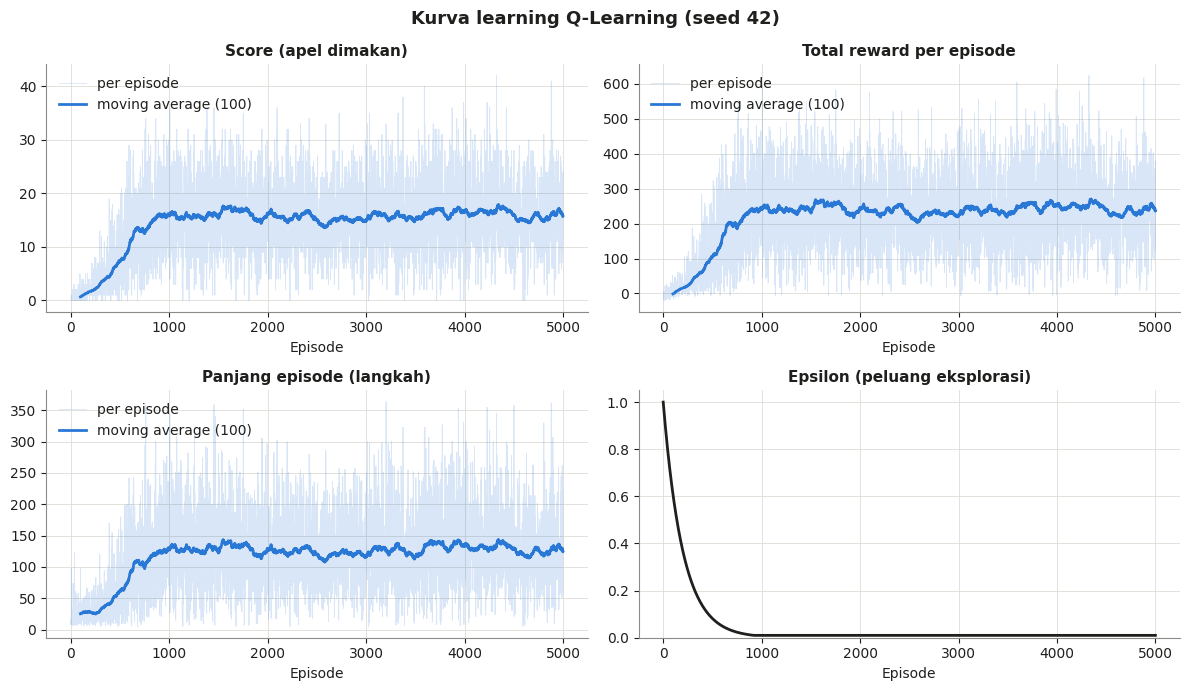

Score maksimum selama training: 42


,Metrik,500 episode pertama,500 episode terakhir
0,Rata-rata score,3.51,15.58
1,Rata-rata total reward,44.41,234.93
2,Rata-rata panjang episode,37.31,124.31


In [7]:
# ===== Kurva learning: score, reward, panjang episode, epsilon =====
def plot_learning(log, color=C_QL, title=''):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7))
    series = [('score', 'Score (apel dimakan)'), ('reward', 'Total reward per episode'),
              ('length', 'Panjang episode (langkah)')]
    for ax, (key, label) in zip(axes.flat, series):
        y = np.asarray(log[key])
        ax.plot(y, color=color, alpha=0.18, lw=0.6, label='per episode')
        ma = moving_average(y, MA_WINDOW)
        ax.plot(np.arange(MA_WINDOW - 1, len(y)), ma, color=color, lw=2, label=f'moving average ({MA_WINDOW})')
        ax.set_title(label); ax.set_xlabel('Episode'); ax.legend(loc='upper left')
    ax = axes[1, 1]
    ax.plot(log['epsilon'], color=INK, lw=2)
    ax.set_title('Epsilon (peluang eksplorasi)'); ax.set_xlabel('Episode'); ax.set_ylim(0, 1.05)
    fig.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

plot_learning(log_ql, C_QL, 'Kurva learning Q-Learning (seed 42)')

n = 500
tbl = pd.DataFrame({
    'Metrik': ['Rata-rata score', 'Rata-rata total reward', 'Rata-rata panjang episode'],
    f'{n} episode pertama': [np.mean(log_ql[k][:n]) for k in ('score', 'reward', 'length')],
    f'{n} episode terakhir': [np.mean(log_ql[k][-n:]) for k in ('score', 'reward', 'length')],
}).round(2)
print("Score maksimum selama training:", max(log_ql['score']))
tbl

### Analisis kurva learning

- **Agent benar-benar belajar.** Rata-rata score naik dari **3,51** pada 500 episode pertama menjadi **15,58** pada 500 episode terakhir. Rata-rata total reward naik dari 44,4 menjadi 234,9, dan rata-rata panjang episode dari 37,3 menjadi 124,3 langkah. Ular bertahan lebih lama dan makan lebih banyak apel karena ia belajar menghindari bahaya dan mendekati apel, bukan karena diberi tahu aturannya.
- **Tiga fase.** (1) Sekitar 0–500 episode: epsilon masih besar, perilaku hampir acak, score rendah. (2) Sekitar 500–1.000 episode: epsilon turun dan Q-table terisi, kurva naik tajam. (3) Setelah sekitar 1.000 episode: kurva mendatar (plateau). Epsilon mencapai batas bawah 0,01 di sekitar episode 920, jadi fase 2 adalah masa transisi dari eksplorasi ke eksploitasi.
- **Plateau bukan berarti sempurna.** Score per episode (garis tipis) tetap sangat bervariasi, dari hampir 0 sampai 42. Sebabnya (a) posisi apel acak, dan (b) state hanya 11 fitur sehingga agent tidak melihat bentuk badannya (dibahas di bagian 8).
- **Ukuran Q-table kecil:** hanya **256 state** yang pernah dikunjungi (cocok dengan perhitungan 4 × 8 × 8 = 256 di bagian 2), sehingga tabel cepat terisi dan Q-Learning tabular layak dipakai.
- **Catatan:** score training (epsilon = 0,01) lebih rendah dari score evaluasi (epsilon = 0) (mis. 15,79 vs 17,97 pada rata-rata 5 seed di bagian 6). Dugaan saya, aksi acak sesekali (1% per langkah) kadang berakibat fatal; dugaan ini tidak diuji terpisah.

## 5. Evaluasi Policy Akhir (epsilon = 0) dan Perbandingan dengan Agent Random

Setelah training, eksplorasi dimatikan (epsilon = 0) sehingga agent memainkan **policy greedy**-nya sendiri. Policy dimainkan selama 100 episode. Agent random dan SARSA dievaluasi pada 100 episode dengan urutan apel yang sama persis, sehingga perbedaan hasil benar-benar berasal dari kualitas policy.

Evaluasi 100 episode, epsilon = 0, seed environment 12345..12444


,Rata-rata score,Std,Maks,Min,Median,Rata-rata reward,Rata-rata panjang,Mati: dinding,Mati: badan,Kelaparan
Agent,,,,,,,,,,
Random (baseline),0.13,0.34,1,0,0.0,-11.22,20.87,99,0,1
Q-Learning,19.47,6.03,36,8,19.0,297.86,160.47,18,82,0
SARSA,18.57,6.48,35,3,18.0,283.85,150.36,13,87,0


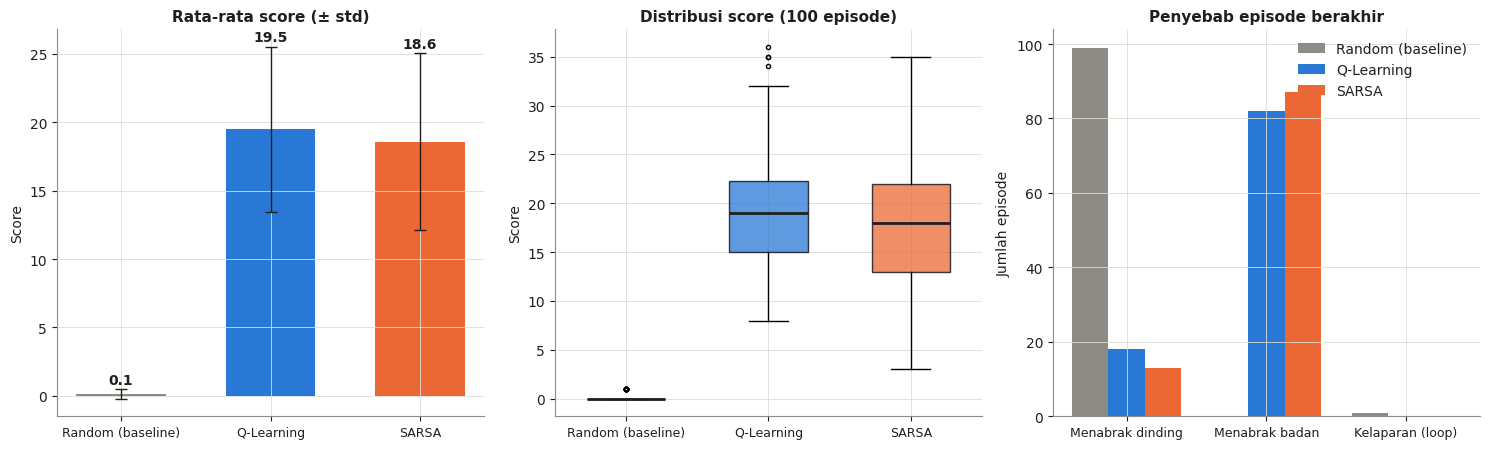

In [8]:
# ===== 6. EVALUASI POLICY AKHIR (epsilon = 0, 100 episode) vs AGENT RANDOM (+ SARSA) =====
agent_sarsa, log_sarsa = train('sarsa', episodes=N_EPISODES, seed=SEED, **HP_MAIN)
agent_rand = RandomAgent(seed=SEED)

EV = {
    'Random (baseline)': evaluate(agent_rand, N_EVAL, EVAL_SEED),
    'Q-Learning':        evaluate(agent_ql,   N_EVAL, EVAL_SEED),
    'SARSA':             evaluate(agent_sarsa, N_EVAL, EVAL_SEED),
}

def summarize(name, ev):
    rs = Counter(ev['reason'])
    return {'Agent': name,
            'Rata-rata score': np.mean(ev['score']), 'Std': np.std(ev['score']),
            'Maks': max(ev['score']), 'Min': min(ev['score']), 'Median': np.median(ev['score']),
            'Rata-rata reward': np.mean(ev['reward']), 'Rata-rata panjang': np.mean(ev['length']),
            'Mati: dinding': rs['wall'], 'Mati: badan': rs['body'], 'Kelaparan': rs['starved']}

df_eval = pd.DataFrame([summarize(k, v) for k, v in EV.items()]).set_index('Agent').round(2)
print(f"Evaluasi {N_EVAL} episode, epsilon = 0, seed environment {EVAL_SEED}..{EVAL_SEED+N_EVAL-1}")
display(df_eval)

# --- Visualisasi: bar rata-rata, box plot distribusi, penyebab kematian ---
names = list(EV.keys()); cols = [C_RANDOM, C_QL, C_SARSA]
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))

ax = axes[0]
means = [np.mean(EV[k]['score']) for k in names]; stds = [np.std(EV[k]['score']) for k in names]
ax.bar(range(3), means, yerr=stds, color=cols, capsize=4, width=0.6, error_kw={'ecolor': INK, 'lw': 1})
for i, m in enumerate(means):
    ax.text(i, m + stds[i] + 0.4, f'{m:.1f}', ha='center', fontweight='bold')
ax.set_xticks(range(3)); ax.set_xticklabels(names, fontsize=9)
ax.set_title('Rata-rata score (± std)'); ax.set_ylabel('Score')

ax = axes[1]
bp = ax.boxplot([EV[k]['score'] for k in names], patch_artist=True, widths=0.55,
                medianprops=dict(color=INK, lw=2), flierprops=dict(marker='o', ms=3, mfc='none'))
for patch, c in zip(bp['boxes'], cols):
    patch.set_facecolor(c); patch.set_alpha(0.75)
ax.set_xticks([1, 2, 3]); ax.set_xticklabels(names, fontsize=9)
ax.set_title('Distribusi score (100 episode)'); ax.set_ylabel('Score')

ax = axes[2]
reasons = ['wall', 'body', 'starved']
w = 0.26
for i, k in enumerate(names):
    cnt = Counter(EV[k]['reason'])
    ax.bar(np.arange(3) + (i - 1) * w, [cnt[r] for r in reasons], width=w, color=cols[i], label=k)
ax.set_xticks(range(3)); ax.set_xticklabels([REASON_ID[r] for r in reasons], fontsize=9)
ax.set_title('Penyebab episode berakhir'); ax.set_ylabel('Jumlah episode'); ax.legend()
plt.tight_layout(); plt.show()

### Analisis evaluasi policy akhir

- **Agent terlatih jauh lebih baik dari random.** Dalam 100 episode dengan seed apel yang sama: Q-Learning rata-rata **19,47** apel (std 6,03, maks **36**, min **8**, median 19), sedangkan agent random rata-rata **0,13** apel (maks 1, min 0). Skor *terburuk* agent terlatih (8) bahkan lebih tinggi dari skor *terbaik* agent random (1), sehingga distribusi keduanya sama sekali tidak tumpang tindih pada box plot.
- **Reward ikut mencerminkan hal ini:** rata-rata total reward 297,9 (Q-Learning) vs -11,2 (random). Agent random rata-rata hanya bertahan 20,9 langkah, kebanyakan karena menabrak dinding (99 dari 100 episode), sedangkan agent terlatih bertahan 160,5 langkah.
- **Cara mati berubah.** Agent terlatih hampir tidak lagi menabrak dinding (18 episode); ia mati terutama karena **menabrak badannya sendiri** (82 episode). Ini konsisten dengan keterbatasan state: agent hanya "melihat" sel yang bersebelahan dengan kepala, sehingga saat ular sudah panjang ia bisa masuk ke ruang buntu yang tidak terlihat dari 11 fitur itu. Tidak ada episode yang berakhir karena kelaparan (0), jadi aturan anti-loop tidak pernah dipicu oleh policy akhir.
- **SARSA** pada seed yang sama mendapat rata-rata 18,57 (maks 35, min 3), yaitu sedikit di bawah Q-Learning. Perbandingan yang lebih adil (banyak seed) ada di bagian 6, karena hasil satu seed bisa kebetulan.

## 6. Pembanding: Q-Learning vs SARSA (multi-seed)

Satu kali training bisa kebetulan bagus atau jelek. Karena itu kedua algoritma dilatih ulang dengan beberapa seed berbeda memakai hyperparameter dasar yang sama, lalu dibandingkan rata-ratanya.

5 seed x 2 algoritma selesai dalam 12.0 detik


,Score training (500 ep. terakhir),Eval rata-rata (mean antar seed),Std antar seed,Eval maks (seluruh seed)
Algoritma,,,,
Q-Learning,15.79,17.97,0.99,34
SARSA,16.40,18.15,1.05,39


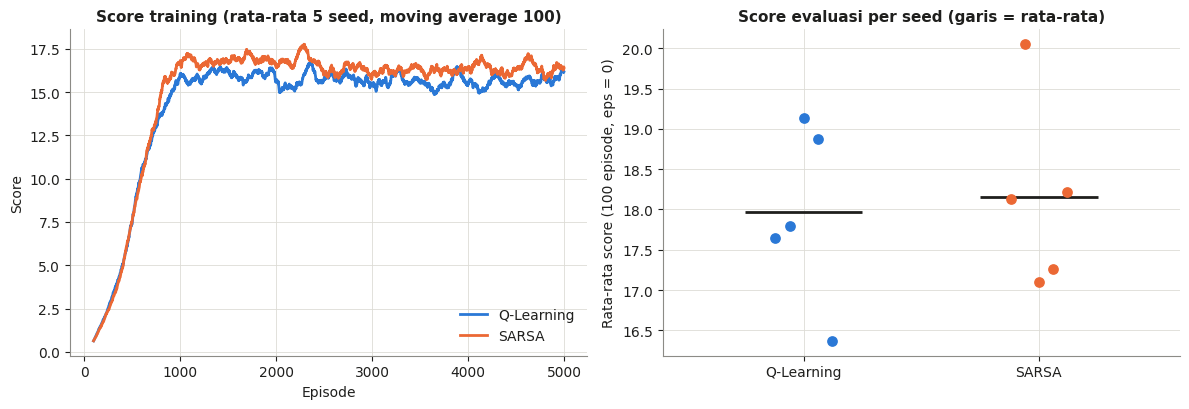

In [9]:
# ===== Perbandingan lebih adil: banyak seed (hasil 1 seed bisa kebetulan) =====
CACHE = {}

def run_config(algo='qlearning', **hp):
    """Latih N_SEEDS agent dengan hyperparameter sama (seed berbeda), lalu evaluasi greedy tiap agent."""
    key = (algo, tuple(sorted(hp.items())))
    if key in CACHE:
        return CACHE[key]
    curves, ev_mean, ev_max, ev_len = [], [], [], []
    for i in range(N_SEEDS):
        ag, lg = train(algo, episodes=N_EPISODES, seed=1000 + i, **hp)
        ev = evaluate(ag, N_EVAL, EVAL_SEED)
        curves.append(lg['score']); ev_mean.append(np.mean(ev['score']))
        ev_max.append(max(ev['score'])); ev_len.append(np.mean(ev['length']))
    curves = np.array(curves)
    CACHE[key] = {'curve': curves.mean(axis=0), 'curve_all': curves, 'ev_mean': np.array(ev_mean),
                  'ev_max': np.array(ev_max), 'ev_len': np.array(ev_len),
                  'train_last': curves[:, -500:].mean()}
    return CACHE[key]

BASE = dict(alpha=0.1, gamma=0.9, eps_decay=0.995)
t0 = time.time()
res_ql    = run_config('qlearning', **BASE)
res_sarsa = run_config('sarsa', **BASE)
print(f"{N_SEEDS} seed x 2 algoritma selesai dalam {time.time()-t0:.1f} detik")

df_algo = pd.DataFrame({
    'Algoritma': ['Q-Learning', 'SARSA'],
    'Score training (500 ep. terakhir)': [res_ql['train_last'], res_sarsa['train_last']],
    'Eval rata-rata (mean antar seed)':  [res_ql['ev_mean'].mean(), res_sarsa['ev_mean'].mean()],
    'Std antar seed':                    [res_ql['ev_mean'].std(), res_sarsa['ev_mean'].std()],
    'Eval maks (seluruh seed)':          [res_ql['ev_max'].max(), res_sarsa['ev_max'].max()],
}).set_index('Algoritma').round(2)
display(df_algo)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
ax = axes[0]
for res, c, lab in [(res_ql, C_QL, 'Q-Learning'), (res_sarsa, C_SARSA, 'SARSA')]:
    ax.plot(np.arange(MA_WINDOW - 1, N_EPISODES), moving_average(res['curve'], MA_WINDOW), color=c, lw=2, label=lab)
ax.set_title(f'Score training (rata-rata {N_SEEDS} seed, moving average {MA_WINDOW})')
ax.set_xlabel('Episode'); ax.set_ylabel('Score'); ax.legend()
ax = axes[1]
for i, (res, c, lab) in enumerate([(res_ql, C_QL, 'Q-Learning'), (res_sarsa, C_SARSA, 'SARSA')]):
    ax.scatter(np.full(N_SEEDS, i) + np.linspace(-0.12, 0.12, N_SEEDS), res['ev_mean'], color=c, s=45, zorder=3)
    ax.hlines(res['ev_mean'].mean(), i - 0.25, i + 0.25, color=INK, lw=2)
ax.set_xticks([0, 1]); ax.set_xticklabels(['Q-Learning', 'SARSA']); ax.set_xlim(-0.6, 1.6)
ax.set_title('Score evaluasi per seed (garis = rata-rata)'); ax.set_ylabel('Rata-rata score (100 episode, eps = 0)')
plt.tight_layout(); plt.show()

### Analisis Q-Learning vs SARSA

- Rata-rata score evaluasi lima seed: Q-Learning **17,97** (std antar seed 0,99) vs SARSA **18,15** (std 1,05). Selisihnya (0,18) jauh lebih kecil dari variasi antar seed, jadi **tidak ada bukti salah satu algoritma lebih baik** pada pengaturan ini. Pada kurva training, SARSA tampak sedikit lebih tinggi (16,40 vs 15,79), tetapi selisih sekecil itu pun masih berada dalam rentang kebisingan antar seed.
- **Pelajaran metodologis:** pada seed 42 (bagian 5) Q-Learning terlihat lebih unggul dari SARSA, tetapi urutannya berbalik jika dirata-rata beberapa seed. Kesimpulan dari satu kali training tidak dapat diandalkan; itulah alasan eksperimen multi-seed dipakai.
- **Mengapa hasilnya mirip?** Perbedaan teoritis keduanya (Q-Learning memakai $\max$, SARSA memakai aksi yang benar-benar diambil) baru terasa bila eksplorasi masih besar dan kesalahan eksplorasi mahal. Pada akhir training epsilon hanya 0,01, sehingga kedua target hampir sama.

## 7. Eksperimen Hyperparameter

Tiga hyperparameter divariasikan **satu per satu** (faktor lain tetap di nilai dasar alpha = 0,1; gamma = 0,9; decay = 0,995). Tiap konfigurasi dilatih dengan beberapa seed. Pengaruhnya diukur lewat:

- kurva learning (score moving average),
- score evaluasi greedy (epsilon = 0) rata-rata antar seed, beserta simpangan baku antar seed,
- kecepatan belajar: episode pertama saat moving average score mencapai ≥ 10.

Eksperimen hyperparameter selesai dalam 58.0 detik (12 konfigurasi x 5 seed)


,Faktor,Nilai,Dasar?,Score training (500 ep. terakhir),Eval rata-rata,Std antar seed,Eval maks,Episode utk MA score >= 10
0,alpha,0.010,,17.58,19.98,1.12,46,606
1,alpha,0.050,,15.92,18.25,0.71,36,613
2,alpha,0.100,ya,15.79,17.97,0.99,34,586
3,alpha,0.300,,15.85,17.83,0.77,41,653
4,alpha,0.700,,13.51,17.33,0.53,40,688
5,gamma,0.500,,16.66,18.15,0.92,36,615
6,gamma,0.800,,16.25,18.41,1.01,39,602
7,gamma,0.900,ya,15.79,17.97,0.99,34,586
8,gamma,0.990,,14.17,15.73,2.58,36,616
9,eps_decay,0.950,,16.52,18.63,0.62,39,152


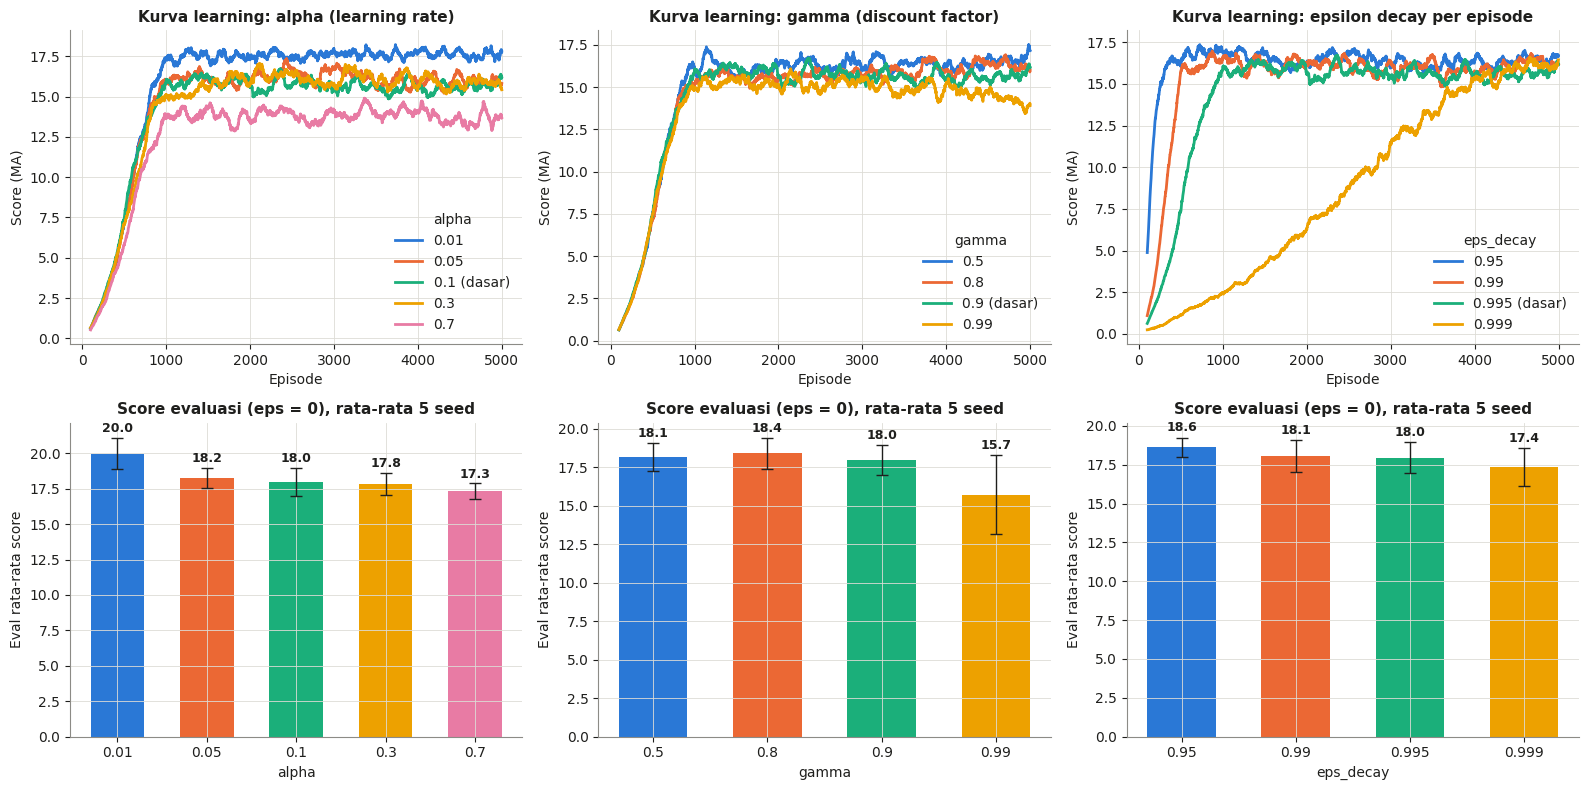

In [10]:
# ===== 7. EKSPERIMEN HYPERPARAMETER (satu faktor diubah, faktor lain tetap di nilai dasar) =====
GRID = {'alpha':     [0.01, 0.05, 0.1, 0.3, 0.7],
        'gamma':     [0.5, 0.8, 0.9, 0.99],
        'eps_decay': [0.95, 0.99, 0.995, 0.999]}
FACTOR_LABEL = {'alpha': 'alpha (learning rate)', 'gamma': 'gamma (discount factor)', 'eps_decay': 'epsilon decay per episode'}

t0 = time.time()
rows, results_hp = [], {}
for factor, values in GRID.items():
    for v in values:
        cfg = dict(BASE); cfg[factor] = v
        r = run_config('qlearning', **cfg)
        results_hp[(factor, v)] = r
        ma = moving_average(r['curve'], MA_WINDOW)
        reach = int(np.argmax(ma >= 10) + MA_WINDOW) if (ma >= 10).any() else np.nan   # kecepatan belajar
        rows.append({'Faktor': factor, 'Nilai': v, 'Dasar?': 'ya' if v == BASE[factor] else '',
                     'Score training (500 ep. terakhir)': r['train_last'],
                     'Eval rata-rata': r['ev_mean'].mean(), 'Std antar seed': r['ev_mean'].std(),
                     'Eval maks': r['ev_max'].max(), 'Episode utk MA score >= 10': reach})
df_hp = pd.DataFrame(rows)
df_hp = df_hp.round({c: 2 for c in df_hp.columns if c not in ('Faktor', 'Nilai', 'Dasar?')})   # Nilai tidak dibulatkan (0.995 tetap 0.995)
print(f"Eksperimen hyperparameter selesai dalam {time.time()-t0:.1f} detik "
      f"({len(CACHE)} konfigurasi x {N_SEEDS} seed)")
display(df_hp)

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, (factor, values) in enumerate(GRID.items()):
    axt, axb = axes[0, j], axes[1, j]
    for i, v in enumerate(values):
        r = results_hp[(factor, v)]
        lab = f'{v}' + (' (dasar)' if v == BASE[factor] else '')
        axt.plot(np.arange(MA_WINDOW - 1, N_EPISODES), moving_average(r['curve'], MA_WINDOW),
                 color=PALETTE[i], lw=2, label=lab)
    axt.set_title(f'Kurva learning: {FACTOR_LABEL[factor]}'); axt.set_xlabel('Episode'); axt.set_ylabel('Score (MA)')
    axt.legend(loc='lower right', title=factor)
    m = [results_hp[(factor, v)]['ev_mean'].mean() for v in values]
    sd = [results_hp[(factor, v)]['ev_mean'].std() for v in values]
    axb.bar(range(len(values)), m, yerr=sd, color=PALETTE[:len(values)], capsize=4, width=0.6, error_kw={'ecolor': INK, 'lw': 1})
    for i, mv in enumerate(m):
        axb.text(i, mv + sd[i] + 0.4, f'{mv:.1f}', ha='center', fontsize=9, fontweight='bold')
    axb.set_xticks(range(len(values))); axb.set_xticklabels([str(v) for v in values])
    axb.set_xlabel(factor); axb.set_ylabel('Eval rata-rata score')
    axb.set_title(f'Score evaluasi (eps = 0), rata-rata {N_SEEDS} seed')
plt.tight_layout(); plt.show()

### Analisis eksperimen hyperparameter

Semua angka di bawah adalah rata-rata 5 seed dengan simpangan baku antar seed sekitar 0,5–1,2 apel (kecuali yang disebut khusus). Selisih yang lebih kecil dari itu **tidak** dianggap bermakna.

**Alpha (learning rate).**
- alpha = 0,01 memberi score evaluasi tertinggi di antara semua konfigurasi satu-faktor (**19,98**), sedangkan alpha = 0,7 terendah di antara nilai alpha (**17,33**; selisihnya dari nilai dasar masih dalam rentang kebisingan antar seed, tetapi score training jelas lebih rendah: 13,51 vs 15,79). Nilai tengah (0,05; 0,1; 0,3) saling berdekatan (18,25; 17,97; 17,83) dan tidak bisa dibedakan.
- Penjelasan yang masuk akal: environment bersifat acak (posisi apel), sehingga alpha besar membuat Q "ikut bergoyang" mengikuti sampel terbaru, sedangkan alpha kecil merata-ratakan banyak pengalaman. Ini penjelasan dugaan; tidak diuji lebih jauh.
- Alpha kecil **tidak** membuat belajar lebih lambat di sini: episode saat moving average mencapai 10 hampir sama untuk semua alpha (606 vs 688). Alasannya, 256 state dikunjungi berulang kali sehingga update kecil pun cukup.

**Gamma (discount factor).**
- gamma 0,5; 0,8; 0,9 sebanding (18,15; 18,41; 17,97). Horizon pendek (gamma = 0,5) sudah cukup karena reward shaping ±1 memberi sinyal langsung di setiap langkah, sehingga agent tidak perlu "melihat jauh".
- gamma = 0,99 **lebih buruk** (**15,73**, dengan variasi antar seed paling besar, std 2,58) dan kurvanya menurun pada akhir training. Dugaan: dengan gamma sangat tinggi, galat estimasi dari state yang tidak lengkap (*aliasing*) ikut terakumulasi lewat bootstrapping, sehingga Q lebih berisik. Ini hipotesis, bukan hasil yang sudah diuji.

**Epsilon decay.**
- Faktor ini paling memengaruhi **kecepatan belajar**: moving average score mencapai 10 pada episode ke-152 (decay 0,95), 351 (0,99), 586 (0,995), dan baru 2700 (0,999), karena pada decay lambat agent lama sekali mengeksplorasi (epsilon masih sekitar 0,08 pada episode 2.500).
- Kualitas akhir hampir sama (18,63; 18,05; 17,97; 17,37), dengan decay paling lambat sedikit terendah. Ruang state yang kecil (256) berarti eksplorasi singkat sudah cukup. Pada ruang state yang jauh lebih besar, decay yang lebih lambat biasanya diperlukan.

**Ringkasan.** Gamma sangat tinggi (0,99) paling jelas merugikan hasil evaluasi; alpha besar (0,7) menurunkan score training dan sedikit menurunkan score evaluasi, sedangkan alpha kecil (0,01) terbaik; epsilon decay menentukan seberapa cepat belajar tetapi tidak banyak mengubah hasil akhir. Konfigurasi terbaik pada eksperimen satu-faktor adalah alpha = 0,01 (**19,98** vs dasar 17,97), selisih sekitar 2 apel; kombinasi antar faktor belum dicoba kecuali pada grid berikut.

### Interaksi alpha × gamma
Untuk melihat apakah dua hyperparameter ini saling memengaruhi, grid 3×3 berikut dievaluasi (decay epsilon tetap).

,gamma=0.5,gamma=0.9,gamma=0.99
alpha=0.05,18.60,18.25,19.21
alpha=0.1,18.15,17.97,15.73
alpha=0.3,18.70,17.83,13.95


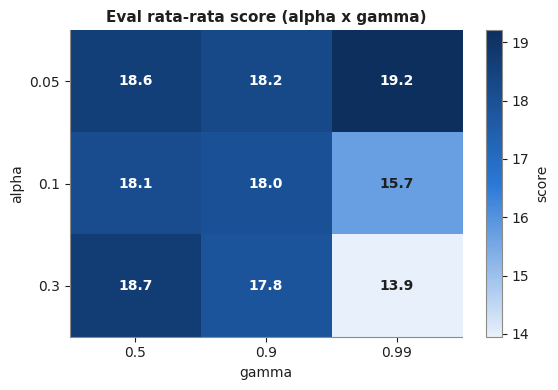

In [11]:
# ===== Interaksi alpha x gamma (decay epsilon tetap di nilai dasar) =====
A_VALS, G_VALS = [0.05, 0.1, 0.3], [0.5, 0.9, 0.99]
Z = np.array([[run_config('qlearning', alpha=a, gamma=g, eps_decay=BASE['eps_decay'])['ev_mean'].mean()
               for g in G_VALS] for a in A_VALS])
df_ag = pd.DataFrame(Z, index=[f'alpha={a}' for a in A_VALS], columns=[f'gamma={g}' for g in G_VALS]).round(2)
display(df_ag)

fig, ax = plt.subplots(figsize=(5.8, 4))
cmap = LinearSegmentedColormap.from_list('seq', ['#e8f0fb', '#2a78d6', '#0d2f5e'])
im = ax.imshow(Z, cmap=cmap, aspect='auto')
for i in range(len(A_VALS)):
    for j in range(len(G_VALS)):
        ax.text(j, i, f'{Z[i, j]:.1f}', ha='center', va='center', fontweight='bold',
                color='white' if Z[i, j] > Z.min() + 0.55 * (Z.max() - Z.min()) else INK)
ax.set_xticks(range(len(G_VALS))); ax.set_xticklabels(G_VALS); ax.set_xlabel('gamma')
ax.set_yticks(range(len(A_VALS))); ax.set_yticklabels(A_VALS); ax.set_ylabel('alpha')
ax.grid(False); ax.set_title('Eval rata-rata score (alpha x gamma)')
plt.colorbar(im, ax=ax, label='score'); plt.tight_layout(); plt.show()

### Analisis interaksi alpha × gamma

- Pada gamma 0,5 dan 0,9, alpha tidak banyak berpengaruh (selisih antar baris kecil: 18,60; 18,15; 18,70 untuk gamma 0,5).
- Pada **gamma 0,99 pengaruh alpha menjadi besar**: alpha 0,05 → **19,21**, alpha 0,1 → 15,73, alpha 0,3 → **13,95**. Jadi gamma tinggi hanya aman bila learning rate kecil. Hal ini sejalan dengan dugaan sebelumnya bahwa target bootstrap dengan gamma tinggi berisik dan alpha besar memperbesar efek kebisingan itu. Perlu diingat grid hanya 3×3 dengan 5 seed, sehingga pola ini indikatif, bukan bukti pasti.

## 8. Visualisasi Value: Nilai Q untuk State Penting

Q-table adalah "pengetahuan" agent. Heatmap berikut menampilkan $Q(s,a)$ untuk 10 state yang dipilih (ular selalu menghadap kanan; "kiri" = menuju atas, "kanan" = menuju bawah pada layar). Kotak hitam menandai aksi yang dipilih policy ($\arg\max_a Q$), sedangkan tabel menampilkan $V(s)=\max_a Q(s,a)$ dan aksi ideal menurut aturan sederhana *"hindari bahaya dulu, lalu pilih arah yang mendekati apel"*.

,Q lurus,Q kiri,Q kanan,V(s)=max Q,Policy pi(s),Aksi ideal,Sesuai?
Skenario,,,,,,,
"Aman, apel di depan",23.25,13.02,13.45,23.25,Lurus,Lurus,ya
"Aman, apel di atas (sisi kiri)",13.25,23.16,8.62,23.16,Belok kiri,Belok kiri,ya
"Aman, apel di bawah (sisi kanan)",13.71,8.55,21.68,21.68,Belok kanan,Belok kanan,ya
"Aman, apel di belakang",1.22,3.17,13.24,13.24,Belok kanan,Lurus / Belok kiri / Belok kanan,ya
"Bahaya di depan, apel di depan",-1.00,-0.95,3.52,3.52,Belok kanan,Belok kiri / Belok kanan,ya
"Bahaya depan, apel kiri-depan",-2.71,12.37,0.70,12.37,Belok kiri,Belok kiri,ya
"Bahaya depan+kiri, apel di atas",-1.00,0.00,7.02,7.02,Belok kanan,Belok kanan,ya
"Bahaya depan+kanan, apel di bawah",-1.00,8.34,-1.00,8.34,Belok kiri,Belok kiri,ya
"Bahaya kiri, apel di atas",9.47,-1.90,1.09,9.47,Lurus,Lurus / Belok kanan,ya


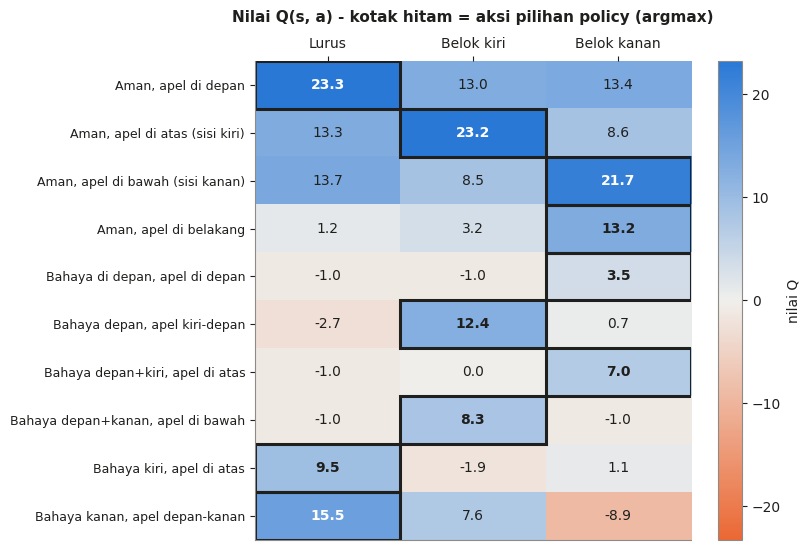

State dengan nilai Q terlatih            : 256
Policy sesuai aturan aman+dekati apel    : 96.5%  (aksi acak hanya 49.0%)
Policy memilih aksi berbahaya padahal ada pilihan aman: 0.0% state


In [12]:
# ===== 8. VISUALISASI VALUE: nilai Q untuk state-state penting =====
def make_state(danger=(0, 0, 0), heading=RIGHT, food=()):
    """Bangun tuple state: danger=(lurus,kiri,kanan), heading=arah absolut, food=arah absolut apel."""
    return tuple(list(danger) + [int(heading == d) for d in range(4)] + [int(d in food) for d in range(4)])

def ideal_actions(state):
    """Aksi 'masuk akal' menurut aturan sederhana: aman dulu, lalu pilih yang mendekati apel."""
    danger, heading, food = state[0:3], state[3:7].index(1), state[7:11]
    new_dir = [heading, (heading - 1) % 4, (heading + 1) % 4]       # arah baru utk lurus/kiri/kanan
    safe = [a for a in range(3) if not danger[a]]
    if not safe:
        return [0, 1, 2]
    good = [a for a in safe if food[new_dir[a]]]
    return good or safe

# Skenario (semua dengan ular menghadap KANAN; atas = kiri relatif, bawah = kanan relatif)
SCENARIOS = [
    ('Aman, apel di depan',                   make_state((0, 0, 0), RIGHT, (RIGHT,))),
    ('Aman, apel di atas (sisi kiri)',        make_state((0, 0, 0), RIGHT, (UP,))),
    ('Aman, apel di bawah (sisi kanan)',      make_state((0, 0, 0), RIGHT, (DOWN,))),
    ('Aman, apel di belakang',                make_state((0, 0, 0), RIGHT, (LEFT,))),
    ('Bahaya di depan, apel di depan',        make_state((1, 0, 0), RIGHT, (RIGHT,))),
    ('Bahaya depan, apel kiri-depan',         make_state((1, 0, 0), RIGHT, (RIGHT, UP))),
    ('Bahaya depan+kiri, apel di atas',       make_state((1, 1, 0), RIGHT, (UP,))),
    ('Bahaya depan+kanan, apel di bawah',     make_state((1, 0, 1), RIGHT, (DOWN,))),
    ('Bahaya kiri, apel di atas',             make_state((0, 1, 0), RIGHT, (UP,))),
    ('Bahaya kanan, apel depan-kanan',        make_state((0, 0, 1), RIGHT, (RIGHT, DOWN))),
]

agent = agent_ql
rows, M = [], np.full((len(SCENARIOS), 3), np.nan)
for i, (name, st) in enumerate(SCENARIOS):
    q = agent.Q.get(st)
    ideal = ideal_actions(st)
    if q is None:
        rows.append({'Skenario': name, 'Q lurus': np.nan, 'Q kiri': np.nan, 'Q kanan': np.nan,
                     'V(s)=max Q': np.nan, 'Policy pi(s)': '(belum dikunjungi)',
                     'Aksi ideal': ' / '.join(ACTION_NAMES[a] for a in ideal), 'Sesuai?': ''})
        continue
    M[i] = q
    best = agent.greedy(st)
    rows.append({'Skenario': name, 'Q lurus': q[0], 'Q kiri': q[1], 'Q kanan': q[2],
                 'V(s)=max Q': max(q), 'Policy pi(s)': ACTION_NAMES[best],
                 'Aksi ideal': ' / '.join(ACTION_NAMES[a] for a in ideal),
                 'Sesuai?': 'ya' if best in ideal else 'TIDAK'})
df_scn = pd.DataFrame(rows).set_index('Skenario').round(2)
display(df_scn)

# --- Heatmap Q-value (diverging: oranye = negatif, abu = 0, biru = positif) ---
vmax = np.nanmax(np.abs(M))
cmap = LinearSegmentedColormap.from_list('div', ['#eb6834', '#f0efec', '#2a78d6'])
fig, ax = plt.subplots(figsize=(8.2, 5.6))
im = ax.imshow(np.ma.masked_invalid(M), cmap=cmap, norm=TwoSlopeNorm(vcenter=0, vmin=-vmax, vmax=vmax), aspect='auto')
for i in range(M.shape[0]):
    if np.isnan(M[i]).all():
        continue
    for j in range(3):
        ax.text(j, i, f'{M[i, j]:.1f}', ha='center', va='center', fontsize=10,
                color='white' if abs(M[i, j]) > 0.62 * vmax else INK, fontweight='bold' if j == int(np.nanargmax(M[i])) else 'normal')
    j = int(np.nanargmax(M[i]))
    ax.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, ec=INK, lw=2.2))   # kotak = argmax (policy)
ax.set_xticks(range(3)); ax.set_xticklabels(ACTION_NAMES)
ax.set_yticks(range(len(SCENARIOS))); ax.set_yticklabels([s[0] for s in SCENARIOS], fontsize=9)
ax.grid(False); ax.xaxis.tick_top()
ax.set_title('Nilai Q(s, a) - kotak hitam = aksi pilihan policy (argmax)', pad=28)
plt.colorbar(im, ax=ax, label='nilai Q'); plt.tight_layout(); plt.show()

# --- Seberapa konsisten policy dengan aturan "aman dulu, lalu dekati apel" di SEMUA state terlatih? ---
learned = [s for s, q in agent.Q.items() if any(v != 0 for v in q)]
agree = np.mean([agent.greedy(s) in ideal_actions(s) for s in learned])
chance = np.mean([len(ideal_actions(s)) / 3 for s in learned])
unsafe = np.mean([s[agent.greedy(s)] == 1 and not all(s[0:3]) for s in learned])
print(f"State dengan nilai Q terlatih            : {len(learned)}")
print(f"Policy sesuai aturan aman+dekati apel    : {agree*100:.1f}%  (aksi acak hanya {chance*100:.1f}%)")
print(f"Policy memilih aksi berbahaya padahal ada pilihan aman: {unsafe*100:.1f}% state")

### Analisis nilai Q dan policy

- **Value mencerminkan strategi.** Pada state aman dengan apel tepat di depan, $Q$(lurus) = **23,2**, jauh lebih tinggi daripada belok (13,0 dan 13,4). Jika apel di samping, nilai tertinggi pindah ke belokan yang tepat. Ketika apel berada di belakang, nilai maksimumnya ($V(s)$) jauh lebih rendah (13,2) karena apel lebih sulit dicapai.
- **Keselamatan didahulukan dari mengejar apel.** Pada "bahaya depan+kiri, apel di atas", apel berada di sisi kiri (yang berbahaya), tetapi policy memilih *belok kanan* (menjauhi apel, tetapi aman) dan menghindari aksi fatal. **10 dari 10 skenario** menghasilkan policy yang sesuai aturan "aman dulu, lalu dekati apel".
- **Nilai −1,0 bukan nilai konvergen.** Beberapa aksi fatal bernilai tepat −1,0. Itu adalah hasil satu kali update dari nol: 0,1 × (−10). Dugaan saya, aksi tersebut hanya dicoba satu kali, lalu tidak pernah dipilih lagi karena aksi lain lebih tinggi. Pelajarannya: policy hanya memerlukan **urutan** nilai yang benar, bukan nilai yang akurat.
- **Konsistensi di seluruh Q-table:** dari 256 state yang terlatih, policy sesuai aturan tersebut pada **96,5%** state (aksi acak hanya akan sesuai ±49,0%), dan **0,0%** state memilih aksi berbahaya padahal ada pilihan aman. 9 state menyimpang dari aturan; ini belum diperiksa satu per satu. Penyimpangan bisa berarti nilai belum konvergen, atau agent mempelajari sesuatu yang lebih jauh daripada aturan sederhana yang rabun jarak.

## 9. Replay Agent Terlatih

Berikut animasi satu episode agent Q-Learning yang sudah dilatih (policy greedy). Episode dipilih dengan score tertinggi dari 30 percobaan berseed berbeda, sehingga ini adalah **contoh terbaik, bukan kinerja rata-rata**. Kinerja rata-rata ada di bagian 5. File GIF juga tersimpan sebagai `snake_replay.gif`.

Episode replay: seed 2030, score 32, 357 langkah, berakhir: Menabrak badan
GIF disimpan: snake_replay.gif (450 KB)


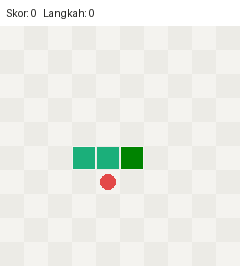

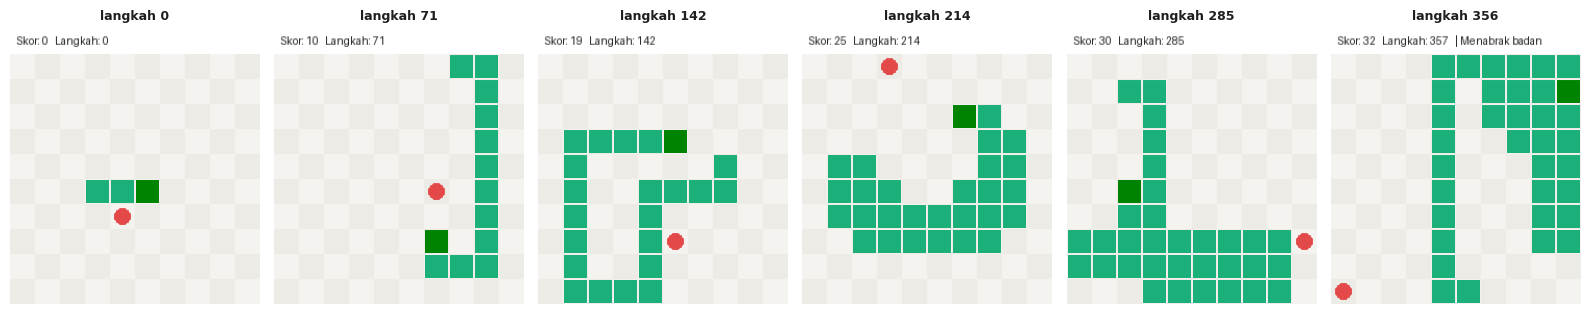

In [13]:
# ===== 9. REPLAY: animasi satu episode agent terlatih (GIF) =====
CELL, HEADER = 24, 26
BG1, BG2 = (244, 243, 239), (236, 235, 230)
C_HEAD, C_BODY, C_APPLE = (0, 131, 0), (27, 175, 122), (227, 73, 72)

def render_frame(snake, food, size, score, steps, note=''):
    img = PILImage.new('RGB', (size * CELL, size * CELL + HEADER), (255, 255, 255))
    d = ImageDraw.Draw(img)
    d.text((6, 7), f"Skor: {score}   Langkah: {steps}   {note}", fill=(31, 31, 29))
    for x in range(size):
        for y in range(size):
            x0, y0 = x * CELL, HEADER + y * CELL
            d.rectangle([x0, y0, x0 + CELL - 1, y0 + CELL - 1], fill=BG1 if (x + y) % 2 == 0 else BG2)
    if food is not None:
        fx, fy = food
        d.ellipse([fx * CELL + 4, HEADER + fy * CELL + 4, fx * CELL + CELL - 5, HEADER + fy * CELL + CELL - 5], fill=C_APPLE)
    for i, (x, y) in enumerate(snake):
        d.rectangle([x * CELL + 1, HEADER + y * CELL + 1, x * CELL + CELL - 2, HEADER + y * CELL + CELL - 2],
                    fill=C_HEAD if i == 0 else C_BODY)
    return img

def play_and_record(agent, seed):
    """Mainkan 1 episode greedy; simpan snapshot tiap langkah."""
    env = SnakeEnv(); s = env.reset(seed=seed); done = False
    snaps = [(list(env.snake), env.food, env.score, env.steps)]
    while not done:
        s, r, done, info = env.step(agent.act(s, explore=False))
        if not done:
            snaps.append((list(env.snake), env.food, env.score, env.steps))
    return snaps, info

# Pilih episode dengan score tertinggi dari 30 percobaan (panjang dibatasi agar GIF tidak terlalu besar)
cands = []
for k in range(30):
    snaps, info = play_and_record(agent_ql, 2024 + k)
    cands.append((info['score'], k, snaps, info))
ok = [c for c in cands if len(c[2]) <= 450] or cands
score_b, kb, snaps, info = max(ok, key=lambda c: c[0])
print(f"Episode replay: seed {2024 + kb}, score {score_b}, {len(snaps)} langkah, berakhir: {REASON_ID[info['reason']]}")

frames = [render_frame(sn, fd, 10, sc, st) for sn, fd, sc, st in snaps]
frames.append(render_frame(snaps[-1][0], snaps[-1][1], 10, snaps[-1][2], info['steps'], f"| {REASON_ID[info['reason']]}"))
durations = [70] * (len(frames) - 1) + [1800]
GIF_PATH = 'snake_replay.gif'
frames[0].save(GIF_PATH, save_all=True, append_images=frames[1:], duration=durations, loop=0)
print(f"GIF disimpan: {GIF_PATH} ({os.path.getsize(GIF_PATH)/1024:.0f} KB)")

try:
    from IPython.display import Image as IPImage, display
    display(IPImage(filename=GIF_PATH))
except Exception as e:
    print("Tampilan GIF tidak tersedia di lingkungan ini:", e)

# Cuplikan statis (jika GIF tidak beranimasi di viewer Anda)
idx = np.linspace(0, len(frames) - 1, 6).astype(int)
fig, axes = plt.subplots(1, 6, figsize=(16, 3.2))
for ax, i in zip(axes, idx):
    ax.imshow(frames[i]); ax.axis('off'); ax.set_title(f'langkah {min(i, snaps[-1][3])}', fontsize=9)
plt.tight_layout(); plt.show()

### Catatan replay

Episode yang ditampilkan (seed 2030) berakhir dengan score **32** setelah 357 langkah dan penyebab akhir **menabrak badan sendiri**. Pada cuplikan, badan ular banyak membentuk jalur memanjang di dekat tepi papan. Akhir episode ini sama dengan penyebab kematian dominan pada evaluasi (82 dari 100 episode); kemungkinan penyebabnya adalah agent tidak bisa melihat bentuk badannya yang jauh dari kepala. Skor episode ini jauh di atas rata-rata evaluasi (19,47) karena sengaja dipilih yang terbaik.

## 10. Ringkasan dan Kesimpulan

In [14]:
# ===== Ringkasan akhir semua eksperimen =====
best_row = df_hp.loc[df_hp['Eval rata-rata'].idxmax()]
summary = pd.DataFrame({
    'Item': ['Random (1 run, 100 ep.)', 'Q-Learning (seed 42, 100 ep.)', 'SARSA (seed 42, 100 ep.)',
             f'Q-Learning rata-rata {N_SEEDS} seed', f'SARSA rata-rata {N_SEEDS} seed',
             f"Hyperparameter terbaik: {best_row['Faktor']}={best_row['Nilai']}"],
    'Rata-rata score': [df_eval.loc['Random (baseline)', 'Rata-rata score'], df_eval.loc['Q-Learning', 'Rata-rata score'],
                        df_eval.loc['SARSA', 'Rata-rata score'], res_ql['ev_mean'].mean(), res_sarsa['ev_mean'].mean(),
                        best_row['Eval rata-rata']],
}).set_index('Item').round(2)
summary

,Rata-rata score
Item,
"Random (1 run, 100 ep.)",0.13
"Q-Learning (seed 42, 100 ep.)",19.47
"SARSA (seed 42, 100 ep.)",18.57
Q-Learning rata-rata 5 seed,17.97
SARSA rata-rata 5 seed,18.15
Hyperparameter terbaik: alpha=0.01,19.98


### Kesimpulan

**Ringkasan hasil.**
- Q-Learning tabular dengan 11 fitur state dan reward shaping mampu belajar bermain Snake dari nol. Dalam 5.000 episode, score rata-rata naik dari 3,5 ke 15,6 (training) dan policy akhir mencapai **19,5** apel rata-rata (maks 36, min 8) pada 100 episode evaluasi, dibanding **0,13** untuk agent random.
- Q-Learning dan SARSA tidak berbeda bermakna (18,0 vs 18,1, lima seed).
- Gamma sangat tinggi (0,99) menurunkan hasil evaluasi, alpha kecil (0,01) memberi hasil terbaik, dan epsilon decay terutama menentukan kecepatan belajar.

**Bukti tiap konsep RL dari eksperimen.**

| Konsep | Bukti dari hasil |
|---|---|
| Agent | `TabularAgent` meningkat dari score 3,5 ke 15,6 hanya lewat pengalaman, tanpa contoh benar/salah |
| Environment | `SnakeEnv` lolos uji sanity; agent random di dalamnya hanya bertahan 21 langkah |
| State | Hanya 256 state efektif; 11 fitur cukup untuk menghindari dinding (hanya 18 kematian dinding pada agent terlatih), tetapi tidak cukup untuk menghindari badan sendiri (82 kematian) |
| Action | Tiga aksi relatif; heatmap menunjukkan aksi berbeda dipilih pada state berbeda |
| Reward | +10 / −10 / ±1 membentuk nilai Q yang konsisten dengan tujuan (apel di depan → $Q$ tertinggi; aksi fatal → negatif) |
| Policy | $\arg\max_a Q$ sesuai aturan aman+dekati apel pada 96,5% state, dan 10 dari 10 skenario uji |
| Value | $Q(s,a)$ dan $V(s)$ pada heatmap; $V$ tinggi saat apel dekat dan jalur aman |
| Belajar lewat interaksi | Kurva learning: eksplorasi (epsilon besar) lalu eksploitasi, plateau setelah sekitar 1.000 episode |
| Evaluasi strategi | 100 episode, epsilon = 0, seed sama untuk semua agent; perbandingan dengan baseline random dan SARSA |

**Keterbatasan**
1. **State aliasing.** Agent tidak melihat badan yang jauh dari kepala, sehingga mati menabrak badan sendiri pada 82% episode evaluasi. Ini kemungkinan faktor pembatas utama score (dibanding pilihan algoritma), tetapi belum diuji dengan state yang lebih kaya.
2. **Jumlah seed kecil (5)** dan eksperimen hyperparameter dilakukan satu faktor sekali waktu (ditambah grid 3×3), sehingga selisih kecil tidak bisa disimpulkan. Tidak ada uji statistik formal.
3. **Evaluasi 100 episode** pada satu rangkaian seed environment; estimasi rata-rata punya galat sampling (std per episode sekitar 6,0).
4. Penjelasan penyebab (mengapa alpha kecil lebih baik, mengapa gamma 0,99 buruk, mengapa training < evaluasi) adalah **dugaan** yang masuk akal, belum diuji dengan eksperimen kontrol.
5. Reward shaping ±1 membuat agent cenderung "serakah"; pengaruhnya terhadap hasil tidak diperbandingkan dengan reward tanpa shaping.

**Pengembangan lanjutan.** (a) Tambahkan fitur state seperti jarak ke badan terdekat atau ruang kosong yang dapat dijangkau (*flood fill*) untuk mengurangi aliasing; (b) bandingkan reward dengan dan tanpa shaping; (c) DQN sederhana untuk state yang lebih kaya (mis. grid sekitar kepala) ketika Q-table tidak lagi muat; (d) lebih banyak seed dan uji signifikansi.